In [1]:
import marimo as mo

# Perfect nested sampling with controllable test problems

Nested sampling (Skilling 2004) computes the Bayesian evidence
Z = ∫ L(θ) π(θ) dθ by tracking the prior volume X that shrinks by a
factor e^{-1/nlive} per iteration, while the live points climb the
likelihood. The *perfect* nested sampler draws each replacement
point **i.i.d. from the constrained prior** {L ≥ L_min} at every
iteration — no MCMC, no correlated chains, no tuning. Deviations of
any practical sampler from this reference are then exactly
quantifiable (see
[Higson et al. 2019, Statistics and Computing 29, 891](https://ui.adsabs.harvard.edu/abs/2019S&C....29..891H/abstract)
and the [perfectns package](https://perfectns.readthedocs.io/en/latest/),
which this module mirrors).

The `ultranest.perfectns` module implements six validation problems
whose constrained regions are known in closed form, so that

- the **true prior volume** V(L_min) of {L ≥ L_min} is known exactly
  (or by fixed-seed Monte Carlo),
- **i.i.d. draws from the constrained region** are available
  (the "rejection" reference sampler), and
- the **true evidence lnZ and information gain H** are known
  analytically or to high accuracy.

This notebook shows the geometry of each problem in 2d, explains how
perfect sampling is achieved, and lists the reference values of lnZ
and H at d=2 and d=10.

In [2]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt

# make the repository importable when the notebook is run from docs/
for _up in ['.', '..', '../..']:
    sys.path.insert(0, os.path.abspath(_up))
    try:
        from ultranest.perfectns import (
            BananaContour,
            GaussContour,
            HyperPyramidContour,
            ShellContour,
            SplitEllipsoidContour,
            UncorrelatedFunnelLRPS,
            box_ball_volume,
        )
        break
    except ImportError:
        sys.path.pop(0)

## The six geometries in 2d

Each problem parameterizes its likelihood contours directly: a scalar
contour coordinate t(x) with a monotone schedule L(t), such that the
constrained region is *exactly* {t(x) ≤ t_min}:

| problem | contours in 2d | region shape |
|---|---|---|
| gauss | ellipses (log-spaced widths) | ellipsoid |
| hyperpyramid | axis-aligned boxes | box |
| shell | concentric annuli | radial shell |
| banana | Rosenbrock banana (warped balls) | curved tube |
| splitellipsoid | two sliding teardrops | two disjoint balls |
| funnel | funnel in (log σ, w) | truncated paraboloid |

The plots below show the log-likelihood over the prior space with
contours at L_max − ΔL for ΔL = 1, 2, 4, 10, 40, … nats.

In [3]:
def make_problems(ndim=2):
    """The six test problems (the funnel has ndim+1 parameters)."""
    return {
        'gauss': GaussContour(ndim),
        'hyperpyramid': HyperPyramidContour(ndim),
        'shell': ShellContour(ndim),
        'banana': BananaContour(ndim),
        'splitellipsoid': SplitEllipsoidContour(ndim),
        'funnel': UncorrelatedFunnelLRPS(ndim, trunc_sigmas=6.0),
    }

def loglike_grid(problem, n=400):
    """Log-likelihood over the 2d prior space of each problem."""
    xs = np.linspace(0.0, 1.0, n)
    X0, X1 = np.meshgrid(xs, xs)
    pts = np.stack([X0.ravel(), X1.ravel()], axis=-1)
    L = problem.loglike(pts).reshape(n, n)
    return xs, L

def loglike_grid_funnel(problem, n=400):
    """Funnel log-likelihood in the (s, dp1) plane at dp2 = 0."""
    ss = np.linspace(-3.0, 3.0, n)  # truncated log(sigma) prior support
    dps = np.linspace(-10.0, 10.0, n)
    S, D1 = np.meshgrid(ss, dps)
    theta = np.stack(
        [np.exp(S.ravel()), D1.ravel(), np.zeros(D1.size)], axis=-1)
    L = problem.loglike(theta).reshape(n, n)
    return ss, L

def contour_levels(L):
    """Contours at Lmax - [1, 2, 4, 10, 40, ...] nats."""
    lmax = L.max()
    deltas = [1.0, 2.0, 4.0]
    while deltas[-1] < (lmax - L.min()):
        deltas.append(deltas[-1] * (4 if len(deltas) % 2 else 2.5))
    return np.sort(lmax - np.array(deltas, dtype=float))

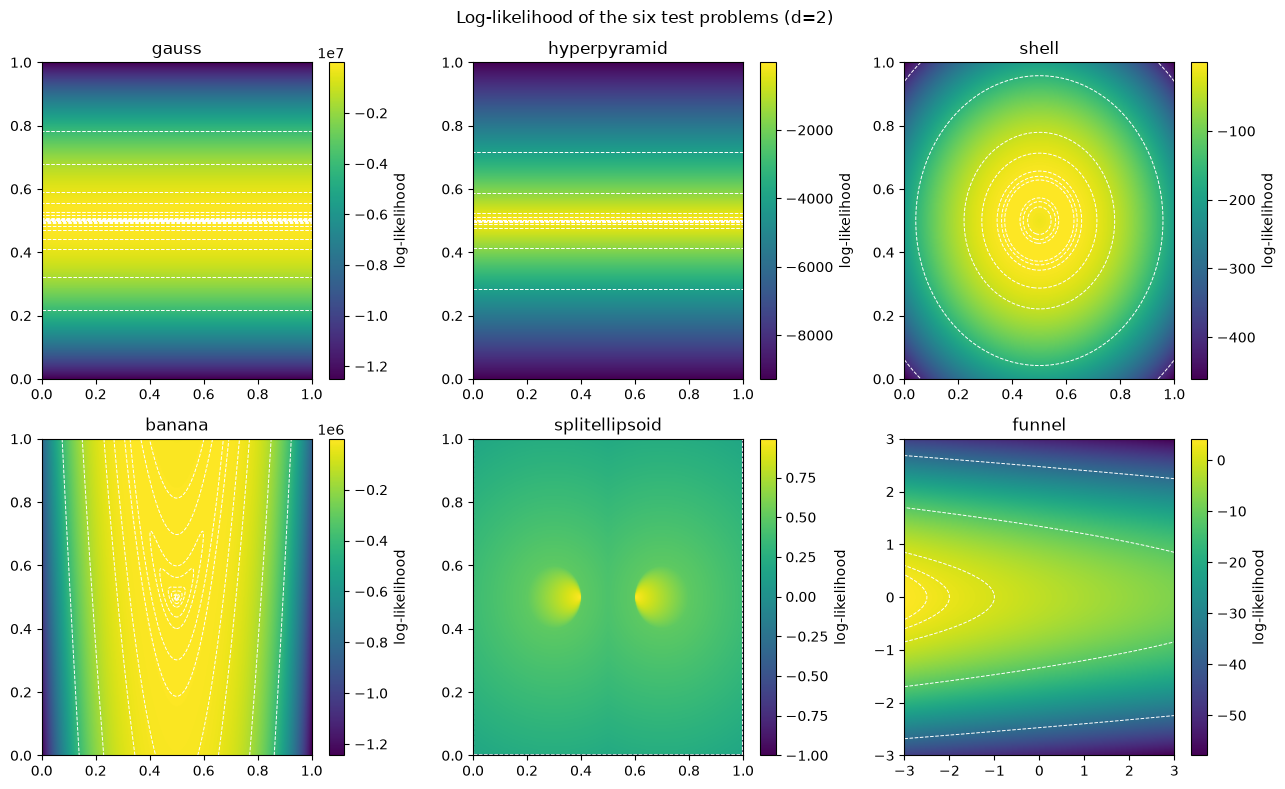

In [4]:
problems2d = make_problems(2)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for _ax, (_name, _problem) in zip(axes.ravel(), problems2d.items()):
    if _name == 'funnel':
        _xs, _L = loglike_grid_funnel(_problem)
    else:
        _xs, _L = loglike_grid(_problem)
    _im = _ax.imshow(
        _L, origin='lower',
        extent=[_xs[0], _xs[-1], _xs[0], _xs[-1]],
        aspect='auto', cmap='viridis')
    _ax.contour(
        _xs, _xs, _L, levels=contour_levels(_L),
        colors='w', linewidths=0.7, linestyles='--')
    _ax.set_title(_name)
    fig.colorbar(_im, ax=_ax, label='log-likelihood')
fig.suptitle('Log-likelihood of the six test problems (d=2)')
fig.tight_layout()
plt.show()

## How perfect nested sampling is achieved

The key is the **contour parameterization**: every problem defines a
scalar coordinate t(x) and a monotone schedule L(t) such that

```
{loglike >= Lmin}  ==  {t(x) <= t_of_L(Lmin)}
```

Because the region is known in closed form, the perfect replacement
step is available:

1. compute t_min = t_of_L(L_min) from the current worst live point;
2. draw candidates **uniformly from {t(x) ≤ t_min}** — exactly, using
   the geometry (uniform in the ellipsoid / box / annulus / warped
   ball / sliding balls), keeping the part inside the prior support;
3. the accepted draws are i.i.d. samples of the constrained prior —
   the *rejection reference* against which practical samplers
   (e.g. slice sampling) are compared.

The true prior volume V(L_min) of the region is likewise known
(analytically for the hyperpyramid and funnel, by fixed-seed Monte
Carlo tabulation for the others), which gives the **true shrinkage**
e^{-1/nlive} per iteration and, through the layer-cake identity

```
Z = ∫ V(l) e^l dl,   H = E_post[log L] - ln Z = ∫ (l+1) V(l) e^l dl / Z - ln Z,
```

the true evidence and information gain.

The panels below demonstrate step 2 for the gauss and banana
problems: the grey points are exact i.i.d. draws from the region
{L ≥ L_min} containing 5% of the prior mass, drawn without any MCMC.

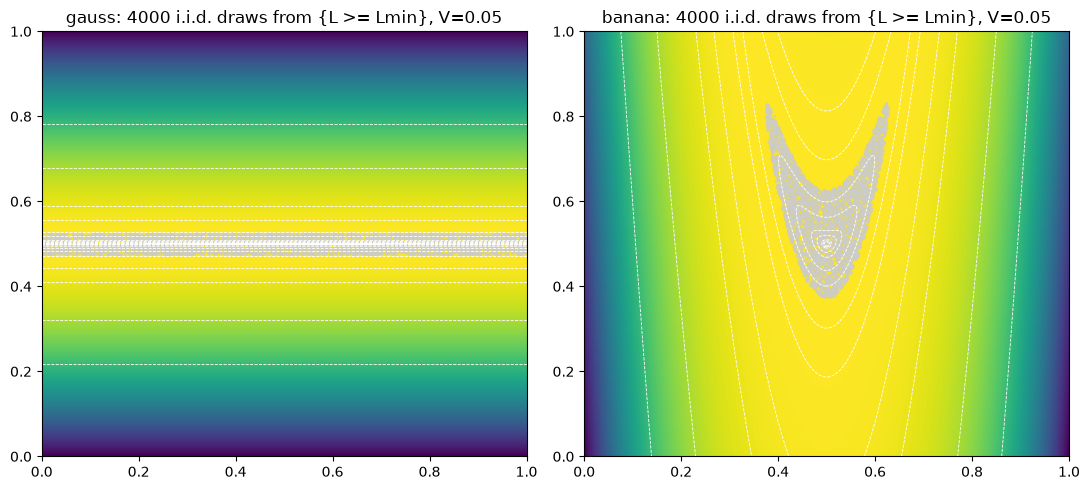

In [5]:
demo_problems = make_problems(2)
rng = np.random.RandomState(1)
fig2, axes2 = plt.subplots(1, 2, figsize=(11, 5))
for _ax, _name in zip(axes2, ['gauss', 'banana']):
    _problem = demo_problems[_name]
    _vol = _problem.make_volume_function(ndraw=int(2e6))
    _lmin = _vol.Lmin_of_volume(0.05)
    _x, _ok = _problem.proposal(_lmin, rng, 4000)
    _samples = _problem.to_u_batch(_x[_ok])
    _xs, _L = loglike_grid(_problem)
    _ax.imshow(
        _L, origin='lower',
        extent=[_xs[0], _xs[-1], _xs[0], _xs[-1]],
        aspect='auto', cmap='viridis')
    _ax.contour(
        _xs, _xs, _L, levels=contour_levels(_L),
        colors='w', linewidths=0.6, linestyles='--')
    _ax.scatter(_samples[:, 0], _samples[:, 1], s=2, c='0.8', alpha=0.5)
    _ax.set_title('%s: %d i.i.d. draws from {L >= Lmin}, V=0.05'
                  % (_name, len(_samples)))
fig2.tight_layout()
plt.show()

## True values of lnZ and H

The table lists reference values at d=2 and d=10, computed with the
most accurate method available for each problem:

- **analytic**: the gauss posterior factorizes into per-axis
  truncated normals (lnZ = Σ ln P(cube_i)); the hyperpyramid and
  shell volumes integrate exactly (analytic box volume, and the
  exact radial CDF of the cube via ball-box volumes); the funnel
  has closed-form values; the gauss, hyperpyramid and funnel
  information gains are analytic.
- **z-space MC** (banana): the constant-Jacobian warping makes the
  posterior a standard normal in z-space, so importance sampling
  with 10^6 draws gives lnZ and H directly.
- **layer-cake MC** (splitellipsoid): the empirical survival
  function of the likelihood under 2×10^6 prior draws, inserted in
  Z = ∫ V(l) e^l dl. Reliable because the splitellipsoid posterior
  occupies a large prior fraction.

In [6]:
def layer_cake_values(problem, ndraw=2000000, seed=0):
    """lnZ and H via the layer-cake identity from fixed-seed prior
    draws: V(l) is the empirical survival function of the likelihood
    under the prior, and Z = ∫ V(l) e^l dl. The survival is exactly 1
    below the smallest sampled likelihood, contributing e^{L_min}."""
    rng = np.random.RandomState(seed)
    nd = len(problem.paramnames)
    us = rng.uniform(size=(ndraw, nd))
    L = problem.loglike(problem.transform(us))
    Ls = np.sort(L)
    n = len(Ls)
    V = 1.0 - (np.arange(n) + 0.5) / n
    c = Ls[-1]  # shift so e^{l-c} <= 1 (no overflow at deep levels)
    li = Ls[:-1]
    Vwe = V[:-1] * np.exp(li - c)
    Z_shift = np.exp(Ls[0] - c) + float(np.trapezoid(Vwe, li))
    I_shift = Ls[0] * np.exp(Ls[0] - c) \
        + float(np.trapezoid((li + 1.0) * Vwe, li))
    lnZ = float(c + np.log(Z_shift))
    H = float(I_shift / Z_shift - lnZ)
    return lnZ, H

In [7]:
from scipy.special import ndtr

def true_values(ndim, ndraw):
    """Reference (lnZ, H, source) per problem at the given dimension,
    using the most accurate method available for each."""
    problems = {
        'gauss': GaussContour(ndim),
        'hyperpyramid': HyperPyramidContour(ndim),
        'shell': ShellContour(ndim),
        'banana': BananaContour(ndim),
        'splitellipsoid': SplitEllipsoidContour(ndim),
        'funnel': UncorrelatedFunnelLRPS(ndim, trunc_sigmas=6.0),
    }
    rows = []
    for name, problem in problems.items():
        if name == 'gauss':
            # the posterior factorizes into per-axis truncated normals
            lo = (0.0 - 0.5) / problem.sigma
            hi = (1.0 - 0.5) / problem.sigma
            lnZ = float(np.log(ndtr(hi) - ndtr(lo)).sum())
            H, src = float(problem.analytic_H()), 'analytic'
        elif name == 'hyperpyramid':
            # layer-cake over the analytic box volume on an l-grid
            ls = np.linspace(-800.0, 0.0, 200001)
            t_min = problem.t_of_L(ls)
            V = np.prod(np.minimum(1.0, 2 * np.outer(t_min,
                                                     problem.sigma)),
                        axis=-1)
            w = np.exp(ls)
            Z = float(np.trapezoid(V * w, ls))
            I = float(np.trapezoid((ls + 1.0) * V * w, ls))
            lnZ = float(np.log(Z))
            H, src = float(problem.analytic_H()), 'analytic'
        elif name == 'shell':
            # layer-cake over the exact radial CDF of the cube
            ls = np.linspace(-800.0, 0.0, 200001)
            t = problem.sigma_shell * np.sqrt(np.maximum(0.0, -2*ls))
            bb = box_ball_volume(problem.ndim, 0.5)
            V = bb.frac((problem.r + t) ** 2) \
                - bb.frac(np.maximum(0.0, problem.r - t) ** 2)
            w = np.exp(ls)
            Z = float(np.trapezoid(V * w, ls))
            I = float(np.trapezoid((ls + 1.0) * V * w, ls))
            lnZ = float(np.log(Z))
            H = float(I / Z - lnZ)
            src = 'analytic'
        elif name == 'banana':
            # constant-Jacobian warping: posterior = standard normal
            # in z-space restricted to the cube preimage
            rng = np.random.RandomState(0)
            z = rng.normal(size=(ndraw, problem.ndim))
            x = problem.from_z(z)
            ok = np.all((x > 0) & (x < 1), axis=1)
            lnZ = float(np.log(ok.mean())
                        + 0.5 * problem.ndim * np.log(2 * np.pi)
                        + np.log(problem.sigma).sum())
            H = float(-0.5 * (z[ok] ** 2).sum(axis=1).mean()) - lnZ
            src = 'z-space MC'
        elif name == 'splitellipsoid':
            lnZ, H = layer_cake_values(problem, ndraw=ndraw)
            src = 'layer-cake MC'
        else:  # funnel
            lnZ = float(problem.analytic_lnZ())
            H, src = float(problem.analytic_H()), 'analytic'
        rows.append((name, lnZ, H, src))
    return rows

In [8]:
rows2 = true_values(2, ndraw=int(2e6))
rows10 = true_values(10, ndraw=int(2e6))
lines = [
    '| problem | lnZ (d=2) | H (d=2) | lnZ (d=10) | H (d=10) |',
    '|---|---|---|---|---|',
]
for (name, lnZ2, H2, src2), (_, lnZ10, H10, src10) in zip(rows2, rows10):
    def _fmt(x, src):
        if src == 'analytic':
            return '%.3f' % x
        return '≈%.3f' % x
    lines.append('| %s | %s | %s | %s | %s |' % (
        name, _fmt(lnZ2, src2), _fmt(H2, src2),
        _fmt(lnZ10, src10), _fmt(H10, src10)))
lines.append('')
lines.append('Unmarked values are analytic; ≈ marks Monte Carlo '
             'estimates (banana: 2×10^6 draws in z-space; '
             'splitellipsoid: 2×10^6 prior draws in the layer cake).')
mo.md('\n'.join(lines))

problem,lnZ (d=2),H (d=2),lnZ (d=10),H (d=10)
gauss,-0.000,8.675,-0.000,43.375
hyperpyramid,-10.671,8.675,-53.375,43.375
shell,-3.458,2.958,-19.334,17.905
banana,≈-9.472,≈8.473,≈-47.361,≈42.363
splitellipsoid,≈0.384,≈0.007,≈0.253,≈0.001
funnel,-5.491,3.654,-17.630,27.003


## References

- Higson, Handley, Hobson & Lasenby (2019),
  *Nested sampling with exact likelihood evaluations*,
  [Statistics and Computing 29, 891](https://ui.adsabs.harvard.edu/abs/2019S&C....29..891H/abstract)
- [perfectns](https://perfectns.readthedocs.io/en/latest/):
  dynamic nested sampling with direct likelihood evaluations,
  the package this module mirrors.
- Skilling (2004), *Nested sampling for general Bayesian computation*.